# Does Hype Sell Games? The Metroid Case

*Final project · WBS Coding School Data Analytics Bootcamp · Javier Villanueva · October 2026*

**Question.** Metroid has a passionate fan base but has always sold modestly. *Metroid Ravenous* (title revealed on 9 September 2026, launch January 2027) generated a lot of buzz. How much of the hype around a Nintendo game's reveal actually goes with sales, and what could that mean for Ravenous compared with *Metroid Dread* (revealed on 15 June 2021, 3.07M copies sold as of 31 December 2022)?

**Short answer**
- Hype has two parts: **how many people care** (the fan base a franchise already has) and **how excited they are** (the jump in interest when the game is revealed).
- Only the first part goes with sales. Fan base, attention in the month after the reveal and trailer views per day correlate with sales (about 0.6). The reveal jump, how long interest stays high, and trailer like and comment rates do not.
- A simple model based on fan base and time on sale puts Ravenous at **about 3.5M copies after two years** (80% range 1.3M to 9.3M), in the same range as Dread.

- **Dashboard:** [Data Studio report](https://datastudio.google.com/reporting/8513a2a0-515f-4f43-9db9-c7558b236bc5) (interactive; the data is stored in BigQuery Sandbox and may stop loading after mid-December 2026)
- **PDF version:** [metroid-hype-dashboard.pdf](https://github.com/jvillanueva-p/metroid-hype/blob/main/dashboard/metroid-hype-dashboard.pdf) (static copy of all 13 pages)

**Narrative rule.** The project does not set out to prove that "Ravenous has more hype than Dread". It asks whether the hype generated could bring more sales. The data is not bent to fit a story, and uncomfortable results are reported as they are.

## How to run this notebook
- Run it from top to bottom (**Kernel > Restart Kernel and Run All Cells**). Collection cells only go to the internet when the CSV they create does not exist yet, or when a `REFRESH_*` switch in section 1 is set to `True`. With the saved CSVs, a full run rebuilds the whole analysis without new downloads.
- Packages: `pandas`, `numpy`, `matplotlib`, `requests`, `lxml` (HTML parser for `pd.read_html`), `python-dotenv`, `pytrends`, `statsmodels`.
- The YouTube API key is read from a `.env` file (`YOUTUBE_API_KEY=...`). The key is never printed, and `.env` is not uploaded to GitHub.
- `games_sheet.csv` was built by hand in Google Sheets (sample group, reveal dates, trailers, search terms) and exported as CSV.
- Google Trends limits the number of requests (error 429). If a collection cell stops, wait a few minutes and run it again: it resumes where it stopped.

## Contents
1. Setup
2. Sales data (Wikipedia)
3. Sample: main group, sample sheet, comparison group
4. Hype data collection: YouTube and Google Trends
5. Metrics and master table
6. Analysis: which hype signals go with sales?
7. Metroid Ravenous: comparison with Dread and sales estimate
8. Tables for the dashboard
9. Findings and limitations

## Notebook names and dashboard names
| Notebook column | Dashboard name | What it measures |
|---|---|---|
| `franchise_size` | Fan base | Searches for the franchise per search for "Nintendo", 90 days before the reveal (× 100 = searches per 100 "Nintendo") |
| `franchise_share_after` | Attention in the month after | The same ratio in the 30 days from the reveal on |
| `hype_lift` | Reveal jump | Mean interest in the 30 days after the reveal ÷ median interest in the 90 days before |
| `days_elevated` | Days of elevated interest | Days (of 30) above the 90th percentile of the pre-reveal days |
| `views_per_day`, `like_rate`, `comment_rate` | Trailer views per day, like rate, comment rate | YouTube statistics of the title-reveal trailer |
| `sales_age_years` | Time on sale | Years between the release and the date of the sales figure |
| `in_group_chart` | Analysis sample | The 40 games with sales and reliable Google Trends signals |

## Files
| File | Section | Content | Dashboard (BigQuery) |
|---|---|---|---|
| `games_sheet.csv` | input | Sample sheet built by hand: group, reveal date, trailer, search terms | |
| `games_raw.csv` | 2 | Wikipedia tables as downloaded (Switch and Switch 2) | |
| `games_clean.csv` | 2.1 | Clean sales table (title, sales, dates, genre, publisher, platform) | |
| `games_to_search.csv` | 3.1 | Main group (Nintendo-published, 4M+ sales, plus Metroid Dread) | |
| `draw_list.csv` | 3.3 | Full order of the comparison draw (drawn games and backups) | |
| `youtube_data.csv` | 4.1 | Trailer views, likes, comments and engagement rates (55 games) | |
| `daily_trends.csv` | 4.2 | Daily Google Trends interest of each franchise (90 days before, 30 after) | |
| `daily_share.csv` | 4.3 | Daily franchise interest next to "Nintendo" in the same query | |
| `hype_results.csv` | 4.4 | Share using the game name (main group and Ravenous, sensitivity only) | |
| `hype_metrics.csv` | 5.1 | Hype Share, Hype Lift, duration and flags per game | |
| `games_master.csv` | 5.3 | One row per game with all metrics, YouTube data, sales and controls | yes |
| `signals_summary.csv` | 6.1 | Correlation of each hype signal with sales, with 95% intervals | yes |
| `fan_base_summary.csv` | 6.2 | Games, median reveal jump and median sales per fan base group | yes |
| `curves_ravenous_dread.csv` | 7.1 | Daily curves of Ravenous and Dread around the reveal | yes |
| `scenario_neighbors.csv` | 7.3 | The 8 games with the fan base closest to Ravenous | yes |
| `explore_curves.csv` | 8 | Daily curve of each game paired with Ravenous (game picker) | yes |
| `lift_results.csv` | input | First Lift collection from an earlier version, only read in 5.2 as a reproducibility check | |

## 1. Setup

Libraries, project constants and the API key. File names, time windows and download switches are defined here once and used in every section.

In [1]:
# Libraries used in the project
import os                                 # Files and environment variables
import time                               # Pauses between Google Trends queries
from datetime import timedelta            # Date arithmetic
from io import StringIO                   # Lets pandas read HTML text as a file

import numpy as np                        # Numbers and random generator
import pandas as pd                       # Data handling
import matplotlib.pyplot as plt           # Charts
import requests                           # HTTP requests to websites and APIs
from dotenv import load_dotenv            # Loads secret keys from the .env file
from pytrends.request import TrendReq     # Unofficial Google Trends client
import statsmodels.formula.api as smf     # Linear regression with formulas (section 7.2)

In [2]:
# Project constants: defined once here and used in every section

# Dates
# The analysis date is fixed, so the notebook returns the same numbers every time it runs.
# It only affects years_on_market and sales_per_year (robustness checks in 6.4)
# and days_online when the YouTube statistics are downloaded again.
TODAY = pd.Timestamp("2026-10-16")          # analysis date of the final version
YESTERDAY = TODAY - timedelta(days=1)       # today's data is incomplete in Google Trends, so the last usable day is yesterday

# Input built by hand in Google Sheets
SHEET_FILE = "games_sheet.csv"

# Files created by the notebook
RAW_FILE = "games_raw.csv"
CLEAN_FILE = "games_clean.csv"
SELECTION_FILE = "games_to_search.csv"
DRAW_FILE = "draw_list.csv"
YOUTUBE_FILE = "youtube_data.csv"
DAILY_FILE = "daily_trends.csv"
SHARE_FILE = "daily_share.csv"
NAME_SHARE_FILE = "hype_results.csv"
METRICS_FILE = "hype_metrics.csv"
OLD_LIFT_FILE = "lift_results.csv"          # first Lift collection, only read in 5.2

# Tables for the dashboard (uploaded to BigQuery, see section 8)
MASTER_FILE = "games_master.csv"
SIGNALS_FILE = "signals_summary.csv"
FAN_BASE_FILE = "fan_base_summary.csv"
CURVES_FILE = "curves_ravenous_dread.csv"
SCENARIO_FILE = "scenario_neighbors.csv"
EXPLORE_FILE = "explore_curves.csv"

# Download switches (False = reuse the saved CSV when it exists)
REFRESH_WIKI = False
REFRESH_YOUTUBE = False

# Google Trends windows
REFERENCE = "Nintendo"      # reference term, queried together with each franchise
BASELINE_DAYS = 90          # days before the reveal = "normal" level
AFTER_DAYS = 30             # days from the reveal on = reaction window
PAUSE_SECONDS = 15          # pause between queries to avoid the 429 rate limit

# YouTube
YOUTUBE_URL = "https://www.googleapis.com/youtube/v3/videos"
OFFICIAL_SOURCES = [        # only these channels are valid for the engagement analysis
    "Nintendo of America",
    "The Official Pokémon YouTube channel",
]

In [3]:
# Load the API key from the .env file (never print it, so it stays private)
load_dotenv()
api_key = os.getenv("YOUTUBE_API_KEY")
print("API key loaded:", api_key is not None)

# Google Trends client
pytrends = TrendReq(hl="en-US", tz=0)

API key loaded: True


## 2. Sales data (Wikipedia)

The lists of best-selling Switch and Switch 2 games are scraped from Wikipedia. Most figures come from Nintendo's official reports; a few come from co-publishers, such as Koei Tecmo for Hyrule Warriors: Age of Calamity and Fire Emblem Warriors: Three Hopes. Both tables are combined into one DataFrame with a `platform` column and saved as `games_raw.csv`, so the analysis always uses the same version of the data, even if Wikipedia changes later. The download only runs when `games_raw.csv` does not exist (or when `REFRESH_WIKI = True`).

Wikipedia only lists games with at least 1 million copies, because Nintendo usually publishes per-title sales only for its million-seller titles on Switch and Switch 2. Figures close to 1.0 are often milestone announcements ("over 1 million"), so they are lower bounds.

In [4]:
def get_wiki_tables(url):
    """Download a Wikipedia page and return only the tables that contain 'Copies sold'."""
    # Wikipedia may block requests that don't identify themselves, so we send a User-Agent
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, headers=headers)
    # match='Copies sold' skips navigation boxes and keeps only the sales table
    return pd.read_html(StringIO(response.text), match="Copies sold")


if os.path.exists(RAW_FILE) and not REFRESH_WIKI:
    print(f"{RAW_FILE} already exists: skipping the download (set REFRESH_WIKI = True to download again)")
else:
    switch_url = "https://en.wikipedia.org/wiki/List_of_best-selling_Nintendo_Switch_video_games"
    switch2_url = "https://en.wikipedia.org/wiki/List_of_best-selling_Nintendo_Switch_2_games"

    switch_tables = get_wiki_tables(switch_url)
    switch2_tables = get_wiki_tables(switch2_url)
    print(len(switch_tables), len(switch2_tables))   # each page should return exactly one table

    # Add a column with the console, so both lists can be combined
    switch_df = switch_tables[0].copy()
    switch_df["platform"] = "Switch"
    switch2_df = switch2_tables[0].copy()
    switch2_df["platform"] = "Switch 2"

    # Combine both lists and save the raw data
    pd.concat([switch_df, switch2_df], ignore_index=True).to_csv(RAW_FILE, index=False)
    print("Downloaded and saved", RAW_FILE)

games_raw.csv already exists: skipping the download (set REFRESH_WIKI = True to download again)


### 2.1 Cleaning

The raw table is cleaned: footnote markers removed, columns renamed to snake_case, sales converted to numbers and dates converted to datetime. The clean table is saved as `games_clean.csv`.

In [5]:
games = pd.read_csv(RAW_FILE)

# Remove footnote markers like [4] or [a] from column names and cells
games.columns = games.columns.str.replace(r"\[.*?\]", "", regex=True).str.strip()
games = games.replace(r"\[.*?\]", "", regex=True)

# Rename columns to snake_case
games = games.rename(columns={
    "Title": "game_title",
    "Copies sold": "sales_millions",
    "As of": "sales_as_of",
    "Release date": "release_date",
    "Genre(s)": "genre",
    "Developer(s)": "developer",
    "Publisher(s)": "publisher",
})

# Keep only the number in the sales column (e.g. '71.53 million' -> 71.53)
games["sales_millions"] = games["sales_millions"].str.extract(r"([\d.]+)").astype(float)

# Convert text dates to datetime; dates that can't be read become empty (NaT)
games["release_date"] = pd.to_datetime(games["release_date"], errors="coerce")
games["sales_as_of"] = pd.to_datetime(games["sales_as_of"], errors="coerce")

games.head()

,game_title,sales_millions,sales_as_of,release_date,genre,developer,publisher,platform
0,Mario Kart 8 Deluxe,71.53,2026-06-30,2017-04-28,Kart racing,Nintendo EPD,Nintendo,Switch
1,Animal Crossing: New Horizons,50.29,2026-06-30,2020-03-20,Social simulation,Nintendo EPD,Nintendo,Switch
2,Super Smash Bros. Ultimate,38.14,2026-06-30,2018-12-07,Fighting,Bandai Namco StudiosSora Ltd.,Nintendo,Switch
3,The Legend of Zelda: Breath of the Wild,34.06,2026-06-30,2017-03-03,Action-adventure,Nintendo EPD,Nintendo,Switch
4,Super Mario Odyssey,30.80,2026-06-30,2017-10-27,Platformer,Nintendo EPD,Nintendo,Switch


In [6]:
# Check for empty values created during cleaning (e.g. dates that couldn't be read)
games.isna().sum()

game_title        0
sales_millions    0
sales_as_of       0
release_date      0
genre             0
developer         0
publisher         0
platform          0
dtype: int64

In [7]:
# Save the clean dataset
games.to_csv(CLEAN_FILE, index=False)
print(games.shape)

(115, 8)


## 3. Sample

The final sample has 55 games in four groups (column `sample_group` in `games_sheet.csv`):

| Group | Games | Rule |
|---|---|---|
| `main` | 39 | Nintendo-published games with 4M+ copies sold, plus Metroid Dread as a justified exception |
| `case` | 1 | Metroid Ravenous (no sales yet) |
| `comparison_random` | 13 | Nintendo-published Switch games under 4M, drawn at random by sales band (section 3.3) |
| `comparison_fixed` | 2 | Kirby Air Riders and Hyrule Warriors: Age of Imprisonment, the only Switch 2 games under 4M (chosen on purpose, so Switch 2 is represented) |

**Rules used for every group**
- `title_reveal_date` is the date the game's *name* was revealed (not an earlier teaser).
- At least 30 days between the title reveal and the release (the minimum in the sample is 36 days).
- Co-published games only enter when Nintendo handles most of the world (only Japan differs).
- "Switch 2 Edition" duplicates of games already in the sample are excluded.
- Bayonetta and Bayonetta 3 stay in the sample; they share one measurement, which is flagged (`shared_measure`) and tested in a sensitivity run.

Of these 55 games, 54 have sales (all but Ravenous). After removing the games with unreliable Google Trends signals (section 5.3), the **analysis sample has 40 games**.

**Why a comparison group:** if only games with 4M+ sales are studied, the outcome is selected, because every game "sold well". The comparison group adds games with lower sales. It is an extremes sample, not a representative sample of all Nintendo games.

### 3.1 Main group

Rule: Nintendo-published games with at least 4M copies sold, plus Metroid Dread as a justified exception (it is the central comparison for Ravenous).

41 games pass the rule. Two of them were left out when the sample sheet was built, because they break the reveal-to-release rule: *Super Mario 3D All-Stars* (released 15 days after its title reveal) and *Pokémon FireRed and LeafGreen* (a re-release launched 7 days after its announcement). That leaves 39 games in the main group.

In [8]:
# Selection rule: Nintendo-published games with at least 4 million copies sold,
# plus Metroid Dread as a justified exception (it is the central case of the project)
SALES_THRESHOLD = 4.0
EXCEPTIONS = ["Metroid Dread"]

# "Nintendo" appears in the publisher text. This also covers values like
# "The Pokémon CompanyNintendo" and "JP: Koei TecmoNA/PAL: Nintendo"
is_nintendo = games["publisher"].str.contains("Nintendo", na=False)
is_top_seller = games["sales_millions"] >= SALES_THRESHOLD
is_exception = games["game_title"].isin(EXCEPTIONS)

# Keep Nintendo games that are either top sellers or listed exceptions
games_selected = games[is_nintendo & (is_top_seller | is_exception)].copy()
games_selected = games_selected.sort_values("sales_millions", ascending=False)

# Check that the exception was found (an empty set means it is there)
print("Exceptions missing:", set(EXCEPTIONS) - set(games_selected["game_title"]))
print(games_selected.shape)   # expected (41, 8): 2 games are left out in the sample sheet (see above)
print(games_selected[["game_title", "sales_millions", "release_date", "platform"]].to_string())

# List of titles to import into Google Sheets (reveal dates and trailers are added by hand there)
games_selected[["game_title"]].to_csv(SELECTION_FILE, index=False)

Exceptions missing: set()
(41, 8)
                                           game_title  sales_millions release_date  platform
0                                 Mario Kart 8 Deluxe           71.53   2017-04-28    Switch
1                       Animal Crossing: New Horizons           50.29   2020-03-20    Switch
2                          Super Smash Bros. Ultimate           38.14   2018-12-07    Switch
3             The Legend of Zelda: Breath of the Wild           34.06   2017-03-03    Switch
4                                 Super Mario Odyssey           30.80   2017-10-27    Switch
5                          Pokémon Scarlet and Violet           28.46   2022-11-18    Switch
6                            Pokémon Sword and Shield           27.26   2019-11-15    Switch
7           The Legend of Zelda: Tears of the Kingdom           22.71   2023-05-12    Switch
8                                   Super Mario Party           21.36   2018-10-05    Switch
9                      New Super Mar

### 3.2 Sample sheet

`games_sheet.csv` is built by hand in Google Sheets: one row per game with the sample group, the reveal date of the title, the trailer (video ID and channel), the search term for the game and the search term for the franchise. Other cells read it from here on.

The sheet already includes the 13 comparison games drawn at random; section 3.3 reruns the draw with the same seed and checks that the sheet matches it.

In [9]:
sheet = pd.read_csv(SHEET_FILE)
sheet = sheet.dropna(subset=["game_title"])
sheet["title_reveal_date"] = pd.to_datetime(sheet["title_reveal_date"])

print(sheet.shape)                                                       # expected (55, 8)
print(sheet["sample_group"].value_counts())                              # main 39, comparison_random 13, comparison_fixed 2, case 1
print("Missing franchise_term:", sheet["franchise_term"].isna().sum())   # expected 0

(55, 8)
sample_group
main                 39
comparison_random    13
comparison_fixed      2
case                  1
Name: count, dtype: int64
Missing franchise_term: 0


### 3.3 Comparison group (stratified random draw)

The games below 4M copies are split into three sales bands and a fixed number of games is drawn from each one. The seed is fixed (`SEED = 2026`), so the draw is reproducible, and the full shuffled order is saved in `draw_list.csv`. If a drawn game failed a check (for example the 30-day rule), the next game of its band in the list (a backup) was used instead. The seed must not be changed.

- **Pool:** Nintendo-published games under 4M that are not already in the original sample (main group and case), not a "Switch 2 Edition" duplicate, not excluded by the co-publisher rule, and not one of the two fixed Switch 2 picks.
- **Bands:** high 2.5 to 4M (draw 5), mid 1.5 to 2.5M (draw 4), low 1.0 to 1.5M (draw 4).
- **Limitation:** Wikipedia lists games from 1M, so "low" means 1M or more, and figures close to 1.0 are milestone lower bounds.
- **Metroid Prime Remastered** (1.09M) is in the pool but was not drawn (it is a backup in the low band). It would have failed the 30-day rule anyway, because it was revealed and released on the same day.

In [10]:
# Chosen on purpose: the only Switch 2 games under 4M, so Switch 2 is represented in the comparison group
FIXED_PICKS = ["Kirby Air Riders", "Hyrule Warriors: Age of Imprisonment"]

# Games already in the original sample (the comparison games are not excluded here, so the pool
# is the same one the draw was made from)
original_titles = set(sheet.loc[sheet["sample_group"].isin(["main", "case"]), "game_title"])

# Candidates: below the threshold, not in the original sample, not a "Switch 2 Edition" duplicate
low = games[
    (games["sales_millions"] < SALES_THRESHOLD)
    & ~games["game_title"].isin(original_titles)
    & ~games["game_title"].str.contains("Switch 2 Edition", case=False, na=False)
].copy()

# Split by publisher: contains "Nintendo" vs empty (empty ones need a manual check)
is_nintendo = low["publisher"].str.contains("Nintendo", na=False)
has_publisher = low["publisher"].notna() & (low["publisher"].astype(str).str.strip() != "")
pool = low[is_nintendo].copy()
missing_publisher = low[~has_publisher]

print("Fixed picks not found in games_clean:", set(FIXED_PICKS) - set(games["game_title"]))   # expected: set()
print("Candidates below threshold (any publisher):", len(low))
print("Nintendo-published candidates:", len(pool))                                           # expected: 49
print("Candidates with empty publisher:", len(missing_publisher))                           # expected: 0

# Empty publisher: these may be merged cells in Wikipedia, so check them by hand
if len(missing_publisher) > 0:
    display(missing_publisher[["game_title", "sales_millions", "developer"]])

# Nintendo-published pool, highest sales first (shows the publisher text for the region rule)
pool[["game_title", "sales_millions", "publisher"]].sort_values("sales_millions", ascending=False)

Fixed picks not found in games_clean: set()
Candidates below threshold (any publisher): 67
Nintendo-published candidates: 49
Candidates with empty publisher: 0


,game_title,sales_millions,publisher
42,1-2-Switch,3.74,Nintendo
43,Pikmin 4,3.48,Nintendo
44,Paper Mario: The Origami King,3.47,Nintendo
45,Yoshi's Crafted World,3.35,Nintendo
46,Super Mario RPG,3.31,Nintendo
49,Mario + Rabbids Sparks of Hope,3.00,NA/PAL: UbisoftJP: Nintendo
50,Super Mario Galaxy 2,2.76,Nintendo
51,New Pokémon Snap,2.74,JP: The Pokémon CompanyNA/PAL: Nintendo
52,Arms,2.72,Nintendo
53,Xenoblade Chronicles 2,2.70,Nintendo


In [11]:
SEED = 2026   # fixed seed so the draw is reproducible
BANDS = {     # band label: (min sales, max sales, how many to draw)
    "high (2.5-4M)": (2.5, 4.0, 5),
    "mid (1.5-2.5M)": (1.5, 2.5, 4),
    "low (1.0-1.5M)": (1.0, 1.5, 4),
}
# Excluded by the co-publisher rule (Nintendo does not distribute in most regions)
REGION_RULE_OUT = ["Mario + Rabbids Sparks of Hope", "Mario + Rabbids Kingdom Battle", "Shin Megami Tensei V"]

# Eligible pool: Nintendo-published, minus the fixed picks and the region-rule exclusions
eligible = pool[~pool["game_title"].isin(FIXED_PICKS + REGION_RULE_OUT)].copy()
print("Eligible games:", len(eligible))   # expected: 44

parts = []
for band, (low_sales, high_sales, n_draw) in BANDS.items():
    # Lower limit included, upper limit excluded
    in_band = eligible[(eligible["sales_millions"] >= low_sales) & (eligible["sales_millions"] < high_sales)]
    shuffled = in_band.sample(frac=1, random_state=SEED)       # whole band in random order
    shuffled = shuffled.assign(band=band, draw_order=range(1, len(shuffled) + 1))
    # First n_draw are drawn; the rest are backups used in order if a drawn game fails a check
    shuffled["status"] = ["draw" if i < n_draw else "backup" for i in range(len(shuffled))]
    parts.append(shuffled)
    print(band, "-> eligible:", len(in_band), "| drawn:", n_draw)

draw_df = pd.concat(parts)
draw_df.to_csv(DRAW_FILE, index=False)   # keep the full order as a record for the README

# Audit: compare the draw with the comparison games that ended up in the sample sheet
in_sheet = set(sheet.loc[sheet["sample_group"] == "comparison_random", "game_title"])
drawn = set(draw_df.loc[draw_df["status"] == "draw", "game_title"])
print("Drawn but not in the sheet (replaced by a backup):", sorted(drawn - in_sheet))
print("In the sheet but not drawn (backups used):", sorted(in_sheet - drawn))

draw_df[["band", "draw_order", "status", "game_title", "sales_millions", "release_date", "publisher"]]

Eligible games: 44
high (2.5-4M) -> eligible: 11 | drawn: 5
mid (1.5-2.5M) -> eligible: 16 | drawn: 4
low (1.0-1.5M) -> eligible: 17 | drawn: 4
Drawn but not in the sheet (replaced by a backup): []
In the sheet but not drawn (backups used): []


,band,draw_order,status,game_title,sales_millions,release_date,publisher
44,high (2.5-4M),1,draw,Paper Mario: The Origami King,3.47,2020-07-17,Nintendo
45,high (2.5-4M),2,draw,Yoshi's Crafted World,3.35,2019-03-29,Nintendo
55,high (2.5-4M),3,draw,Mario Strikers: Battle League,2.54,2022-06-10,Nintendo
42,high (2.5-4M),4,draw,1-2-Switch,3.74,2017-03-03,Nintendo
46,high (2.5-4M),5,draw,Super Mario RPG,3.31,2023-11-17,Nintendo
54,high (2.5-4M),6,backup,Super Mario Galaxy,2.60,2025-10-02,Nintendo
52,high (2.5-4M),7,backup,Arms,2.72,2017-06-16,Nintendo
50,high (2.5-4M),8,backup,Super Mario Galaxy 2,2.76,2025-10-02,Nintendo
53,high (2.5-4M),9,backup,Xenoblade Chronicles 2,2.70,2017-12-01,Nintendo
51,high (2.5-4M),10,backup,New Pokémon Snap,2.74,2021-04-30,JP: The Pokémon CompanyNA/PAL: Nintendo


## 4. Hype data collection

Two sources are used for every game in `games_sheet.csv`:
- **YouTube Data API:** views, likes and comments of the title-reveal trailer (engagement).
- **Google Trends:** daily search interest of the franchise, 90 days before and 30 days after the title reveal.

Google Trends does not return the number of searches. It returns an index from 0 to 100 (integers), scaled **per query**: 100 is the highest day of that query. Values from different queries cannot be compared, only the ratio of two terms inside the same query can. Google also samples its data, so repeating a query can change values by about 1 point.

### 4.1 YouTube trailers

Downloads views, likes and comments for the title-reveal trailer of every game.

**Which channels count for engagement.** Like and comment rates depend on who watches the video, so they are only comparable between similar audiences. Two official channels are used:
- **Nintendo of America:** Nintendo's main English-language channel, where most title reveals are published and which reaches the widest international audience. It is the primary source (45 of the 55 games).
- **The Official Pokémon YouTube channel:** Pokémon games are usually revealed in Pokémon Presents, which premiere on The Pokémon Company's channel instead of Nintendo of America (4 games).

The other 6 games stay in the sample but are excluded from the engagement analysis:
- **Third-party re-uploads** (GameSpot, IGN; 5 games): no official upload of the reveal trailer was available, and news channels have a different audience and reach.
- **Nintendo's Japanese channel** (1 game, Yoshi's Crafted World): official, but aimed at a different audience, so its rates are not comparable with the English-language channels.

Likes divided by views is the main engagement rate (`like_rate`), because some videos have comments disabled (`comment_rate` is secondary). Games that share one video are flagged so that the video counts only once. Videos with comments off return 0 comments, so they are stored as empty and not as 0.

The download only runs when `youtube_data.csv` does not exist (or when `REFRESH_YOUTUBE = True`), so the numbers do not change every time the notebook runs.

In [12]:
if os.path.exists(YOUTUBE_FILE) and not REFRESH_YOUTUBE:
    youtube_df = pd.read_csv(YOUTUBE_FILE, parse_dates=["title_reveal_date", "published_date"])
    print(f"Loaded {YOUTUBE_FILE} (set REFRESH_YOUTUBE = True to download the statistics again)")
else:
    # 1. Download statistics for each unique video (games sharing a video are requested once)
    video_ids = sheet["trailer_id"].unique().tolist()
    videos = []
    for i in range(0, len(video_ids), 50):              # the API accepts up to 50 IDs per request
        chunk = video_ids[i:i + 50]
        params = {"part": "snippet,statistics", "id": ",".join(chunk), "key": api_key}
        response = requests.get(YOUTUBE_URL, params=params)
        response.raise_for_status()
        for item in response.json().get("items", []):
            stats = item["statistics"]
            videos.append({
                "trailer_id": item["id"],
                "video_title": item["snippet"]["title"],
                "channel": item["snippet"]["channelTitle"],
                "published_at": item["snippet"]["publishedAt"],
                # Fields are missing when likes are hidden: keep them empty instead of counting them as zero
                "views": int(stats["viewCount"]) if "viewCount" in stats else None,
                "likes": int(stats["likeCount"]) if "likeCount" in stats else None,
                "comments": int(stats["commentCount"]) if "commentCount" in stats else None,
            })
    videos_df = pd.DataFrame(videos)
    print("Missing videos:", set(video_ids) - set(videos_df["trailer_id"]))   # expected: set()

    # 2. Join the sheet with the video data (one row per game)
    youtube_df = sheet.merge(videos_df, on="trailer_id", how="left")
    youtube_df["published_date"] = pd.to_datetime(youtube_df["published_at"]).dt.tz_convert(None).dt.normalize()

    # 3. Flags for review
    youtube_df["date_gap_days"] = (youtube_df["published_date"] - youtube_df["title_reveal_date"]).dt.days
    youtube_df["date_mismatch"] = youtube_df["date_gap_days"].abs() > 1           # video date far from the reveal date
    youtube_df["shared_video"] = youtube_df["trailer_id"].duplicated(keep=False)  # same video used by several games
    youtube_df["engagement_valid"] = youtube_df["trailer_source"].isin(OFFICIAL_SOURCES)

    # 4. Engagement rates (total views favor older videos, so rates are safer to compare)
    youtube_df["days_online"] = (TODAY - youtube_df["published_date"]).dt.days.clip(lower=1)
    youtube_df["like_rate"] = youtube_df["likes"] / youtube_df["views"]            # main metric
    youtube_df["comment_rate"] = youtube_df["comments"] / youtube_df["views"]      # secondary
    youtube_df["views_per_day"] = youtube_df["views"] / youtube_df["days_online"]  # biased towards newer videos

    # 5. Videos with comments turned off return 0 comments: a rate of exactly 0 means "comments off", not "no comments"
    comments_off = youtube_df["comments"] == 0
    youtube_df["comments"] = youtube_df["comments"].astype(float)
    youtube_df.loc[comments_off, ["comments", "comment_rate"]] = None

    youtube_df.to_csv(YOUTUBE_FILE, index=False)
    print("Downloaded and saved", YOUTUBE_FILE)

print(youtube_df.shape)   # expected (55, 23)

Loaded youtube_data.csv (set REFRESH_YOUTUBE = True to download the statistics again)
(55, 23)


In [13]:
# Checks (they work whether the data was downloaded or loaded from the CSV)
print("Valid for engagement (official channels) vs excluded:")
print(youtube_df["engagement_valid"].value_counts())

# Games whose trailer has comments turned off (stored as empty, not as 0)
no_comments = youtube_df.loc[youtube_df["comments"].isna(), "game_title"].tolist()
print(f"\nGames with comments turned off: {len(no_comments)}")   # expected: 8
print(no_comments)

# Videos whose publish date is more than 1 day away from the reveal date (expected: 0)
mismatch = youtube_df.loc[youtube_df["date_mismatch"], ["game_title", "title_reveal_date", "published_date", "date_gap_days"]]
print(f"\nVideos published more than 1 day away from the reveal: {len(mismatch)}")   # expected: 0
if len(mismatch) > 0:
    display(mismatch)   # show the table only if there is something to check

Valid for engagement (official channels) vs excluded:
engagement_valid
True     49
False     6
Name: count, dtype: int64

Games with comments turned off: 8
['Animal Crossing: New Horizons', 'Splatoon 2', "Super Mario 3D World + Bowser's Fury", 'Super Mario Maker 2', 'Kirby and the Forgotten Land', 'Pokémon Pokopia', "Yoshi's Crafted World", 'Kirby Air Riders']

Videos published more than 1 day away from the reveal: 0


### 4.2 Google Trends: daily interest of each franchise (for Hype Lift and duration)

One query per franchise (a single term), daily data. `day_offset` is 0 on the reveal day, negative before and positive after. The same helper (`collect_daily`) is used in 4.3: it saves after every game, skips the games already saved, and stops with a message on error 429 (run the cell again to continue). Games with the same franchise and reveal date (for example the two Bayonetta) are queried only once.

In [14]:
def collect_daily(output_file, fetch_function):
    """Run fetch_function(franchise_term, reveal_date) for every game in the sheet and append
    the result to output_file. Games already in the file are skipped, so the cell can be rerun."""
    done = set(pd.read_csv(output_file)["game_title"]) if os.path.exists(output_file) else set()
    cache = {}   # games with the same franchise and reveal date are queried only once

    for _, row in sheet.iterrows():
        if row["game_title"] in done:
            continue
        key = (row["franchise_term"], row["title_reveal_date"])
        try:
            if key not in cache:
                cache[key] = fetch_function(*key)
                time.sleep(PAUSE_SECONDS)   # pause to avoid the 429 rate limit
        except Exception as e:
            # Usually a 429 (rate limit): wait a few minutes and run the cell again, it resumes
            print(f"Stopped at {row['game_title']}: {e}")
            break
        series = cache[key]
        if series is None:
            print("No data for:", row["game_title"])
            continue
        series = series.copy()
        series.insert(0, "game_title", row["game_title"])
        # Save after every game so a 429 never loses progress
        series.to_csv(output_file, mode="a", header=not os.path.exists(output_file), index=False)
        print("Saved:", row["game_title"])

    saved = pd.read_csv(output_file)
    print(saved.groupby("game_title").size().value_counts())   # expected: 120 rows for each of the 55 games

In [15]:
def get_daily_series(franchise_term, reveal_date):
    """Daily interest of one franchise term: 90 days before the reveal and 30 days from the reveal on."""
    reveal = pd.to_datetime(reveal_date)
    start = reveal - timedelta(days=BASELINE_DAYS)
    end = min(reveal + timedelta(days=AFTER_DAYS - 1), YESTERDAY)
    pytrends.build_payload([franchise_term], timeframe=f"{start:%Y-%m-%d} {end:%Y-%m-%d}")
    df = pytrends.interest_over_time()
    if df.empty:
        return None
    out = df[[franchise_term]].rename(columns={franchise_term: "interest"}).reset_index()
    # day_offset: negative = days before the reveal, 0 = reveal day, positive = after
    out["day_offset"] = (out["date"] - reveal).dt.days
    return out


collect_daily(DAILY_FILE, get_daily_series)

120    55
Name: count, dtype: int64


### 4.3 Google Trends: franchise next to "Nintendo" (for Hype Share)

The franchise term and "Nintendo" go in the **same query**, so their values are on the same 0 to 100 scale and their ratio can be interpreted: it shows how big the franchise is relative to Nintendo as a whole.

In [16]:
def get_franchise_vs_nintendo(franchise_term, reveal_date):
    """Daily interest of the franchise and of the reference term "Nintendo" in the same query."""
    reveal = pd.to_datetime(reveal_date)
    start = reveal - timedelta(days=BASELINE_DAYS)
    end = min(reveal + timedelta(days=AFTER_DAYS - 1), YESTERDAY)
    # Two terms in the same query, so their values ARE comparable with each other
    pytrends.build_payload([franchise_term, REFERENCE], timeframe=f"{start:%Y-%m-%d} {end:%Y-%m-%d}")
    df = pytrends.interest_over_time()
    if df.empty:
        return None
    out = df[[franchise_term, REFERENCE]].rename(
        columns={franchise_term: "franchise_interest", REFERENCE: "nintendo_interest"}).reset_index()
    out["day_offset"] = (out["date"] - reveal).dt.days   # negative = before the reveal
    return out


collect_daily(SHARE_FILE, get_franchise_vs_nintendo)

120    55
Name: count, dtype: int64


### 4.4 Share using the game name (main group and Ravenous, sensitivity only)

First version of the Hype Share: the game name (for example "metroid dread") divided by "Nintendo" in the 30 days after the reveal. It is kept only as a sensitivity check and only for the 40 games of the main group and Ravenous (the comparison group was added later), because the game name **undercounts** attention: people search for the franchise, not for the full title (Ravenous 0.012 vs Dread 0.027 by name, but 0.071 vs 0.077 at franchise level). The 60-day version is a control and is empty for games without enough days (Metroid Ravenous).

In [17]:
MAIN_DAYS = 30        # main window
CONTROL_DAYS = 60     # control window (only for games with enough data)


def get_hype_windows(search_term, reveal_date):
    """Share (game interest / reference interest) for the 30 and 60 days after the reveal."""
    start = pd.to_datetime(reveal_date)
    # Never ask for future days (Metroid Ravenous does not have 60 days yet)
    end = min(start + timedelta(days=CONTROL_DAYS - 1), YESTERDAY)
    pytrends.build_payload([search_term, REFERENCE], timeframe=f"{start:%Y-%m-%d} {end:%Y-%m-%d}")
    df = pytrends.interest_over_time()

    # No data returned: keep the row empty instead of crashing
    if df.empty:
        return {"days_available": 0, "game_sum_30": None, "ref_sum_30": None,
                "hype_30": float("nan"), "hype_60": None}

    # One query for both windows keeps them on the same 0-100 scale
    main = df.iloc[:MAIN_DAYS]
    result = {
        "days_available": len(df),
        "game_sum_30": main[search_term].sum(),
        "ref_sum_30": main[REFERENCE].sum(),
    }
    result["hype_30"] = result["game_sum_30"] / result["ref_sum_30"]
    # Control window only if all 60 days are available
    result["hype_60"] = df[search_term].sum() / df[REFERENCE].sum() if len(df) >= CONTROL_DAYS else None
    return result

In [18]:
# Only the main group and Ravenous (40 games); the comparison games are not measured by game name
sheet_original = sheet[sheet["sample_group"].isin(["main", "case"])]

# Resume support: skip games that already have a result saved
done = set(pd.read_csv(NAME_SHARE_FILE)["game_title"]) if os.path.exists(NAME_SHARE_FILE) else set()

for _, row in sheet_original.iterrows():
    if row["game_title"] in done:
        continue
    try:
        result = get_hype_windows(row["search_term"], row["title_reveal_date"])
    except Exception as e:
        # Usually a 429 (rate limit): wait a few minutes and run this cell again, it resumes
        print(f"Stopped at {row['game_title']}: {e}")
        break
    record = {"game_title": row["game_title"], "search_term": row["search_term"], **result}
    # Save after every game so a 429 never loses progress
    pd.DataFrame([record]).to_csv(
        NAME_SHARE_FILE, mode="a", header=not os.path.exists(NAME_SHARE_FILE), index=False)
    print(f"{row['game_title']}: {result['hype_30']:.4f}")
    time.sleep(PAUSE_SECONDS)

name_share_df = pd.read_csv(NAME_SHARE_FILE)
print(name_share_df.shape)   # expected: (40, 7)
name_share_df[["game_title", "game_sum_30", "ref_sum_30", "hype_30", "hype_60", "days_available"]].sort_values("hype_30", ascending=False)

(40, 7)


,game_title,game_sum_30,ref_sum_30,hype_30,hype_60,days_available
6,Pokémon Sword and Shield,277,2149,0.128897,0.081998,60
3,The Legend of Zelda: Breath of the Wild,96,1082,0.088725,0.046547,60
2,Super Smash Bros. Ultimate,88,1182,0.074450,0.068627,60
5,Pokémon Scarlet and Violet,137,2179,0.062873,0.039405,60
12,Mario Kart World,41,853,0.048066,0.030540,60
11,Super Mario Bros. Wonder,63,2143,0.029398,0.022338,60
10,Nintendo Switch Sports,62,2152,0.028810,0.020524,60
38,Metroid Dread,42,1566,0.026820,0.014817,60
25,Tomodachi Life: Living the Dream,20,869,0.023015,0.014025,60
7,The Legend of Zelda: Tears of the Kingdom,41,2046,0.020039,0.009863,60


## 5. Metrics and master table

### Metric definitions

**Hype Share (franchise level)**: franchise interest divided by "Nintendo" interest, summed over a window, both terms in the same query.
- `franchise_size` (dashboard: **Fan base**): Share in the 90 days before the reveal (how big the franchise already was).
- `franchise_share_after` (dashboard: **Attention in the month after**): Share in the 30 days from the reveal on. **Primary metric.**
- `franchise_share_gain`: after minus before (a difference, so a tiny baseline is not a problem).
- `franchise_signal`: raw franchise volume in the 30 days after; low values mean noise.

**Hype Lift (reaction to the reveal)**: single-term query.
- `baseline_median`: median of the 90 days before the reveal (robust to small spikes, such as a leak).
- `after_mean`: mean of the 30 days from the reveal on.
- `hype_lift` (dashboard: **Reveal jump**): `after_mean / baseline_median`.
- `log_lift`: `log2((after_mean + 1) / (baseline_median + 1))`. 0 = no change, 1 = doubled, 2 = four times, negative = drop. **Primary metric.**
- The main analysis (6.1) and the dashboard use `hype_lift`, because it is easier to read (2.0 = twice the normal level). `log_lift` is the version declared as primary and is used in the robustness checks (6.4). Both rank the games almost identically (Spearman 0.999 in the analysis sample).

**Duration**
- `days_elevated` (dashboard: **Days of elevated interest**): days (of 30) above the 90th percentile of the pre-reveal days. About 3 are expected by chance.
- `days_elevated_late`: same for days 15 to 29. About 1.5 are expected by chance.

**Flags (rows excluded from the metric they affect)**
- `low_signal_franchise`: `franchise_signal <= 10`.
- `low_signal_lift`: `baseline_median < 5` (a tiny baseline inflates the ratio). Lift and duration also favor dormant franchises.
- `no_baseline`: `baseline_median == 0`.

### 5.1 Metrics per game

In [19]:
daily = pd.read_csv(DAILY_FILE)
share_daily = pd.read_csv(SHARE_FILE)


def single_term_metrics(g):
    """Hype Lift and duration of one game (single-term daily series)."""
    before = g.loc[g["day_offset"] < 0, "interest"]    # 90 days before the reveal
    after = g.loc[g["day_offset"] >= 0]                # reveal day + 29 days after
    baseline = before.median()                         # "normal" level before the reveal
    after_mean = after["interest"].mean()
    threshold = before.quantile(0.90)                  # unusually high = above 90% of the pre-reveal days
    elevated = after["interest"] > threshold
    return pd.Series({
        "baseline_median": baseline,
        "after_mean": after_mean,
        "hype_lift": after_mean / baseline if baseline > 0 else float("nan"),   # empty if baseline is 0
        "log_lift": np.log2((after_mean + 1) / (baseline + 1)),                 # smoothed log-lift
        "days_elevated": int(elevated.sum()),                                   # out of 30 (chance: ~3)
        "days_elevated_late": int((elevated & (after["day_offset"] >= 15)).sum()),  # out of 15 (chance: ~1.5)
    })


def franchise_share_metrics(g):
    """Hype Share of one game (franchise vs Nintendo in the same query)."""
    before = g[g["day_offset"] < 0]
    after = g[g["day_offset"] >= 0]
    size = before["franchise_interest"].sum() / before["nintendo_interest"].sum()
    share_after = after["franchise_interest"].sum() / after["nintendo_interest"].sum()
    return pd.Series({
        "franchise_size": size,                        # franchise vs Nintendo before the reveal
        "franchise_share_after": share_after,          # same ratio in the 30 days after the reveal
        "franchise_share_gain": share_after - size,    # rise in Nintendo units
        "franchise_signal": after["franchise_interest"].sum(),   # raw volume, to spot noisy cases
    })


trends_metrics = daily.groupby("game_title")[["day_offset", "interest"]].apply(single_term_metrics).reset_index()
share_metrics = share_daily.groupby("game_title")[["day_offset", "franchise_interest", "nintendo_interest"]] \
                           .apply(franchise_share_metrics).reset_index()

metrics = trends_metrics.merge(share_metrics, on="game_title").merge(
    sheet[["game_title", "sample_group", "franchise_term"]], on="game_title")

# Low-signal flags
metrics["low_signal_lift"] = metrics["baseline_median"] < 5
metrics["no_baseline"] = metrics["baseline_median"] == 0
metrics["low_signal_franchise"] = metrics["franchise_signal"] <= 10
metrics.to_csv(METRICS_FILE, index=False)

print(metrics.shape)
print(metrics.groupby("sample_group")[["low_signal_lift", "no_baseline", "low_signal_franchise"]].sum())

(55, 16)
                   low_signal_lift  no_baseline  low_signal_franchise
sample_group                                                         
case                             0            0                     0
comparison_fixed                 0            0                     1
comparison_random                6            3                     5
main                             5            3                     4


### 5.2 Checks

Google samples its data, so the same query can return slightly different values. The first Lift collection (`lift_results.csv`, the 40 games of the main group and Ravenous) is compared with this one: the differences should be tiny (at most about 1 point).

In [20]:
# Reproducibility check: same games measured in the first collection vs this one
if os.path.exists(OLD_LIFT_FILE):
    old = pd.read_csv(OLD_LIFT_FILE)[["game_title", "baseline_median", "after_mean"]]
    check = metrics.merge(old, on="game_title", suffixes=("_new", "_old"))
    print("Games compared:", len(check))
    print("Max abs difference, baseline:", (check["baseline_median_new"] - check["baseline_median_old"]).abs().max())
    print("Max abs difference, after mean:", (check["after_mean_new"] - check["after_mean_old"]).abs().max())
else:
    print(OLD_LIFT_FILE, "not found: check skipped")

# The 15 comparison games
metrics.loc[metrics["sample_group"].str.startswith("comparison"),
            ["game_title", "sample_group", "baseline_median", "log_lift", "days_elevated",
             "franchise_size", "franchise_share_after", "franchise_signal"]].round(3)

Games compared: 40
Max abs difference, baseline: 1.0
Max abs difference, after mean: 0.6333333333333329


,game_title,sample_group,baseline_median,log_lift,days_elevated,franchise_size,franchise_share_after,franchise_signal
0,1-2-Switch,comparison_random,0.0,4.059,26.0,0.000,0.000,0.0
2,Bayonetta,comparison_random,8.0,1.176,30.0,0.002,0.025,34.0
3,Bayonetta 3,comparison_random,8.0,1.176,30.0,0.002,0.025,34.0
4,Big Brain Academy: Brain vs. Brain,comparison_random,0.0,3.548,5.0,0.000,0.000,0.0
8,Fire Emblem Warriors: Three Hopes,comparison_random,34.5,0.335,7.0,0.032,0.053,40.0
10,Game Builder Garage,comparison_random,0.0,3.831,26.0,0.000,0.001,1.0
12,Hyrule Warriors: Age of Imprisonment,comparison_fixed,8.0,1.241,23.0,0.000,0.002,2.0
13,Kirby Air Riders,comparison_fixed,30.0,0.099,3.0,0.152,0.107,92.0
18,Mario Kart Live: Home Circuit,comparison_random,51.0,0.065,5.0,0.089,0.105,202.0
21,Mario Strikers: Battle League,comparison_random,2.0,2.243,30.0,0.000,0.008,6.0


### 5.3 Master table

One row per game (55): hype metrics, YouTube data, sales and control variables. This is the main table of the dashboard.

Extra columns created here:
- `years_on_market`: years from the release to the analysis date. Used as the age control in the robustness checks (6.4).
- `sales_age_days`: days from the release to the date of the sales figure. In years (`sales_age_years`, computed in 6 and 7.2) this is the **time on sale** control of the main analysis and the regression. It measures how long each game had been selling when its figure was reported, which makes games with figures from different dates comparable (Switch 2 figures are still immature).
- `reveal_to_release_days`: days between the title reveal and the release (rule: at least 30).
- `sales_per_year`: sales divided by years on the market (robustness check in 6.4).
- `shared_measure`: games with the same franchise and reveal date share one Trends measurement (BDSP and Arceus, Bayonetta and Bayonetta 3). Tested in a sensitivity run.
- `engagement_use`: valid for the engagement analysis (official channel and not a shared video).
- `sales_tier`: `high_4M+` or `low_under_4M` (Metroid Dread falls in the low tier).
- `in_group_chart`: the **analysis sample** (40 games): sales available, reliable fan base signal (`low_signal_franchise` is False) and reliable jump signal (`low_signal_lift` is False). The 14 games left out:
  - franchise too rare in Google Trends to measure a fan base (`franchise_signal <= 10`, 10 games): 1-2-Switch, Big Brain Academy, Clubhouse Games, Game Builder Garage, Hyrule Warriors: Age of Imprisonment, Luigi's Mansion 3, Mario Strikers, Mario Tennis Aces, Miitopia, Ring Fit Adventure;
  - normal interest too low to measure a jump (`baseline_median < 5`, 4 more games): Hyrule Warriors: Age of Calamity, Nintendo Switch Sports, Super Mario RPG, Tomodachi Life.
- `fan_base_group`, `fan_base_order`: three equal-sized groups by fan base (tertiles), computed on the analysis sample (results in 6.2).
- Metroid Ravenous is not in the Wikipedia sales lists yet, so its platform (Switch 2) is filled in by hand.

In [21]:
youtube_cols = ["game_title", "title_reveal_date", "trailer_source", "views", "likes", "comments",
                "like_rate", "comment_rate", "views_per_day", "days_online", "shared_video", "engagement_valid"]
games_cols = ["game_title", "sales_millions", "sales_as_of", "release_date", "genre", "platform"]
name_share_cols = ["game_title", "game_sum_30", "hype_30"]   # game-name Share, only for the main group and Ravenous (sensitivity)

master = (metrics
          .merge(youtube_df[youtube_cols], on="game_title", how="left")
          .merge(pd.read_csv(CLEAN_FILE)[games_cols], on="game_title", how="left")
          .merge(pd.read_csv(NAME_SHARE_FILE)[name_share_cols], on="game_title", how="left"))

# Dates and controls
for col in ["title_reveal_date", "release_date", "sales_as_of"]:
    master[col] = pd.to_datetime(master[col], errors="coerce")   # unparsable dates become empty
master["years_on_market"] = (TODAY - master["release_date"]).dt.days / 365.25
master["reveal_to_release_days"] = (master["release_date"] - master["title_reveal_date"]).dt.days
master["sales_age_days"] = (master["sales_as_of"] - master["release_date"]).dt.days   # how mature the sales figure is
master["sales_per_year"] = master["sales_millions"] / master["years_on_market"]

# Flags and groups
master["shared_measure"] = master.duplicated(subset=["franchise_term", "title_reveal_date"], keep=False)  # same franchise and reveal date
master["engagement_use"] = master["engagement_valid"] & ~master["shared_video"]                          # valid for engagement analysis
master["sales_tier"] = master["sales_millions"].apply(
    lambda s: None if pd.isna(s) else ("high_4M+" if s >= 4 else "low_under_4M"))

# Fan base groups for the dashboard: three equal-sized groups (tertiles) by fan base size,
# built only from games with sales and reliable Trends signals (40 games)
master["in_group_chart"] = (master["sales_millions"].notna()
                            & ~master["low_signal_franchise"]
                            & ~master["low_signal_lift"])
_, fan_base_cutoffs = pd.qcut(master.loc[master["in_group_chart"], "franchise_size"], 3, retbins=True)
fan_base_cutoffs[0], fan_base_cutoffs[-1] = -np.inf, np.inf   # open the outer edges so every game (incl. Ravenous) gets a group
master["fan_base_group"] = pd.cut(master["franchise_size"], bins=fan_base_cutoffs,
                                  labels=["Small fan base", "Medium fan base", "Large fan base"])
master["fan_base_order"] = master["fan_base_group"].cat.codes + 1   # 1, 2, 3: used to sort the bars in Data Studio

# Ravenous is not in the Wikipedia sales lists yet, so its platform is filled in manually
master.loc[master["game_title"] == "Metroid Ravenous", "platform"] = "Switch 2"   # change if the platform is different

master.to_csv(MASTER_FILE, index=False)

# Checks
print(master.shape)                                                                                  # expected (55, 44)
print("Games without sales:", master.loc[master["sales_millions"].isna(), "game_title"].tolist())   # expected: Ravenous only
print("Games without YouTube data:", master.loc[master["views"].isna(), "game_title"].tolist())     # expected: none
print("Missing sales_as_of:", master["sales_as_of"].isna().sum(),
      "| missing release_date:", master["release_date"].isna().sum())                              # expected: 1 and 1 (Ravenous)
print("Min reveal_to_release_days:", master["reveal_to_release_days"].min())                        # expected: >= 30
print("Shared measure:", master.loc[master["shared_measure"], "game_title"].tolist())
print(master["platform"].value_counts())                                                            # expected: Switch 49, Switch 2 6
print("Analysis sample:", master["in_group_chart"].sum(), "games")                                  # expected: 40
print(master.loc[master["in_group_chart"], "fan_base_group"].value_counts().sort_index())          # expected: 14 / 13 / 13

# Sales range per sample group
print(master.groupby("sample_group")["sales_millions"].describe().round(2))

(55, 44)
Games without sales: ['Metroid Ravenous']
Games without YouTube data: []
Missing sales_as_of: 1 | missing release_date: 1
Min reveal_to_release_days: 36.0
Shared measure: ['Bayonetta', 'Bayonetta 3', 'Pokémon Brilliant Diamond and Shining Pearl', 'Pokémon Legends: Arceus']
platform
Switch      49
Switch 2     6
Name: count, dtype: int64
Analysis sample: 40 games
fan_base_group
Small fan base     14
Medium fan base    13
Large fan base     13
Name: count, dtype: int64
                   count   mean    std   min   25%    50%    75%    max
sample_group                                                           
case                 0.0    NaN    NaN   NaN   NaN    NaN    NaN    NaN
comparison_fixed     2.0   1.45   0.64  1.00  1.23   1.45   1.67   1.90
comparison_random   13.0   2.14   1.01  1.00  1.24   1.79   3.31   3.74
main                39.0  15.89  14.12  3.07  4.89  13.60  18.71  71.53


## 6. Analysis: which hype signals go with sales?

**Analysis sample:** the 40 games in `in_group_chart` (sales available and reliable Google Trends signals, see 5.3).

**Signals**, split into two families:

| Family | Signals |
|---|---|
| How many people care | Fan base before the reveal, attention in the month after, trailer views per day |
| How excited they are | Reveal jump, days of elevated interest, trailer like rate, trailer comment rate |

**Method**
- **Spearman rank correlation** with sales. It uses ranks, so it is robust to the very skewed sales (1M to 71.5M).
- **Partial correlation controlling for time on sale** (`sales_age_years`): a game that had been on sale longer when its figure was reported had more time to sell.
- **95% bootstrap intervals** (2,000 resamples, fixed seed). A signal has a clear link when its interval does not cross 0. The intervals assume a random sample; ours is designed, so they are a little optimistic. Games of the same franchise are not independent either; check 5 in 6.4 tests this.
- **Declared before the analysis:** the two primary metrics were attention after the reveal (Hype Share) and the reveal jump (Hype Lift). The other signals are exploratory, so a chance hit is possible.

In [22]:
# Shared tools for section 6 (has_sales is also used in 7.3)

def partial_rank_corr(df, x, y="sales_millions", control="sales_age_years"):
    """Spearman correlation between x and y after removing the effect of a control variable.
    Rank the three columns, remove the part of x and y that the control explains
    (straight-line fit on the ranks), then correlate what is left."""
    r = df[[x, y, control]].dropna().rank()
    res_x = r[x] - np.polyval(np.polyfit(r[control], r[x], 1), r[control])
    res_y = r[y] - np.polyval(np.polyfit(r[control], r[y], 1), r[control])
    return np.corrcoef(res_x, res_y)[0, 1]


has_sales = master["sales_millions"].notna()   # Ravenous has no sales yet

# Analysis sample: the 40 games with sales and reliable Trends signals (defined in 5.3)
analysis_df = master[master["in_group_chart"]].copy()
analysis_df["sales_age_years"] = analysis_df["sales_age_days"] / 365.25   # time on sale when the figure was reported
print("Analysis sample:", len(analysis_df), "games")   # expected: 40

# Rows trusted for each metric (flags from section 5), used by the checks in 6.3 and 6.4
trusted = {
    "franchise_size":        ~master["low_signal_franchise"],
    "franchise_share_after": ~master["low_signal_franchise"],
    "franchise_share_gain":  ~master["low_signal_franchise"],
    "log_lift":              ~master["low_signal_lift"],
    "days_elevated":         ~master["low_signal_lift"],
    "days_elevated_late":    ~master["low_signal_lift"],
    "like_rate":             master["engagement_use"],
    "comment_rate":          master["engagement_use"],
}

Analysis sample: 40 games


### 6.1 Which hype signals go with sales? (main result)

Each of the seven signals is correlated with sales on the analysis sample, controlling for time on sale. YouTube signals use only valid trailers (official channel, video not shared with another game), so they have fewer games: 33, and 26 for comments, because some videos have comments turned off. The table is saved as `signals_summary.csv` for the dashboard.

In [23]:
# Which hype signals go with sales? Partial rank correlation with sales, controlling for time on sale
# Each signal: column -> (dashboard label, family)
signals = {
    "franchise_size":        ("Fan base before the reveal",   "How many people care"),
    "franchise_share_after": ("Attention in the month after", "How many people care"),
    "views_per_day":         ("Trailer views per day",        "How many people care"),
    "hype_lift":             ("Reveal jump",                  "How excited they are"),
    "days_elevated":         ("Days of elevated interest",    "How excited they are"),
    "like_rate":             ("Trailer like rate",            "How excited they are"),
    "comment_rate":          ("Trailer comment rate",         "How excited they are"),
}
youtube_signals = ["views_per_day", "like_rate", "comment_rate"]

rng = np.random.default_rng(2026)   # fixed seed so the intervals are reproducible
rows = []
for col, (label, signal_type) in signals.items():
    # YouTube signals: only valid, non-shared trailers
    df = analysis_df[analysis_df["engagement_use"]] if col in youtube_signals else analysis_df
    df = df.dropna(subset=[col])
    corr = partial_rank_corr(df, col)
    # Bootstrap: resample the games 2,000 times to get a 95% range for the correlation
    boots = [partial_rank_corr(df.sample(len(df), replace=True, random_state=int(rng.integers(1e9))), col)
             for _ in range(2000)]
    low, high = np.nanpercentile(boots, [2.5, 97.5])
    rows.append({"signal": label, "signal_type": signal_type, "correlation": round(corr, 2),
                 "ci_low": round(low, 2), "ci_high": round(high, 2), "n_games": len(df),
                 "clear_link": bool(low > 0 or high < 0)})   # True if the 95% range does not cross zero

signals_summary = pd.DataFrame(rows)
signals_summary.to_csv(SIGNALS_FILE, index=False)
print(signals_summary)

                         signal           signal_type  correlation  ci_low  \
0    Fan base before the reveal  How many people care         0.59    0.30   
1  Attention in the month after  How many people care         0.59    0.34   
2         Trailer views per day  How many people care         0.56    0.23   
3                   Reveal jump  How excited they are        -0.18   -0.49   
4     Days of elevated interest  How excited they are        -0.12   -0.46   
5             Trailer like rate  How excited they are         0.02   -0.42   
6          Trailer comment rate  How excited they are         0.05   -0.38   

   ci_high  n_games  clear_link  
0     0.77       40        True  
1     0.76       40        True  
2     0.76       33        True  
3     0.21       40       False  
4     0.26       40       False  
5     0.38       33       False  
6     0.45       26       False  


### 6.2 Fan base groups: small fan bases jump the most but sell the least

The 40 games are split into three equal-sized groups by fan base (tertiles, created in 5.3). For each group: number of games, median reveal jump and median sales. The medians are computed here and saved as `fan_base_summary.csv`, because Data Studio's MEDIAN is approximate and would show slightly different numbers.

In [24]:
# Cut-offs between the groups, in searches per 100 "Nintendo"
print("Fan base cut-offs (per 100 Nintendo):", (fan_base_cutoffs[1:3] * 100).round(1))   # expected: about 5.5 and 22.0

# Group summary for the dashboard: exact medians computed here,
# so Data Studio shows the same numbers as the notebook
fan_base_summary = (master[master["in_group_chart"]]
                    .groupby(["fan_base_group", "fan_base_order"], observed=True)
                    .agg(games=("game_title", "size"),
                         median_spike=("hype_lift", "median"),
                         median_sales=("sales_millions", "median"))
                    .reset_index())

# Highlight label used in Data Studio: Metroid (Dread and Ravenous) is in the small fan base group
fan_base_summary["group_highlight"] = np.where(fan_base_summary["fan_base_group"] == "Small fan base",
                                               "Metroid's group", "Other groups")
fan_base_summary[["median_spike", "median_sales"]] = fan_base_summary[["median_spike", "median_sales"]].round(2)

fan_base_summary.to_csv(FAN_BASE_FILE, index=False)
print(fan_base_summary)   # expected: 14 / 13 / 13 games, jump 1.72 / 1.07 / 1.07, sales 4.04 / 8.42 / 15.07

Fan base cut-offs (per 100 Nintendo): [ 5.5 22. ]
    fan_base_group  fan_base_order  games  median_spike  median_sales  \
0   Small fan base               1     14          1.72          4.04   
1  Medium fan base               2     13          1.07          8.42   
2   Large fan base               3     13          1.07         15.07   

   group_highlight  
0  Metroid's group  
1     Other groups  
2     Other groups  


### 6.3 Does the reveal add anything beyond the fan base?

Attention after the reveal (`franchise_share_after`) is almost the same thing as the fan base before it (`franchise_size`). The key question is whether the reveal adds information once the size of the franchise is known. The partial correlation below controls for `franchise_size`. It uses the 44 games with sales and a reliable fan base signal (the jump flag is not needed here). The second table compares the medians of the high sellers (4M+) with the rest.

The same question is tested on the 40-game sample in the regression of 7.2, where the reveal jump is added to the model.

In [25]:
# Does the reveal add anything beyond franchise size? (partial Spearman controlling for franchise_size)
size_df = master[has_sales & trusted["franchise_share_after"]]   # 44 games with a reliable fan base signal
size_df_clean = size_df[~size_df["shared_measure"]]

for label, d in [("all games", size_df), ("without shared measure", size_df_clean)]:
    print(label, "n =", len(d))
    for metric in ["franchise_share_after", "franchise_share_gain"]:
        rho = partial_rank_corr(d, metric, control="franchise_size")
        print("  ", metric, "| controlling for franchise_size:", round(rho, 2))

# Medians by sales tier (only reliable rows for each metric)
rows = []
for metric in ["franchise_size", "franchise_share_after", "log_lift", "days_elevated", "like_rate"]:
    d = master[has_sales & trusted[metric]]
    med = d.groupby("sales_tier")[metric].median().round(3)
    rows.append(med.rename(metric))
print(pd.concat(rows, axis=1).T)

all games n = 44
   franchise_share_after | controlling for franchise_size: -0.0
   franchise_share_gain | controlling for franchise_size: -0.03
without shared measure n = 40
   franchise_share_after | controlling for franchise_size: -0.03
   franchise_share_gain | controlling for franchise_size: 0.02
sales_tier             high_4M+  low_under_4M
franchise_size            0.166         0.016
franchise_share_after     0.198         0.038
log_lift                  0.284         1.176
days_elevated             8.000        25.500
like_rate                 0.020         0.027


### 6.4 Robustness checks

These checks use the earlier specification of the analysis, before the 40-game sample was fixed: each metric keeps all the games where *that* metric is reliable (36 to 44 games), and the age control is `years_on_market` (release to analysis date). If the conclusion also holds here, it does not depend on those choices.
1. **Correlations with and without the games that share a Trends measurement** (BDSP, Arceus, Bayonetta, Bayonetta 3), raw and controlling for age.
2. **Sales per year on the market** as the outcome. It reduces the advantage of older games but favors young ones, so it is a sensitivity check, not a replacement.
3. **Bootstrap 95% intervals** (2,000 resamples, fixed seed) for the raw correlations.
4. **Leave-one-out:** the correlation is recomputed removing one game at a time, to see whether a single game (for example Mario Kart 8 Deluxe) drives the result.
5. **Franchises, not games:** games of the same franchise are not independent (7 Pokémon, 5 Super Mario and 5 Zelda games in the analysis sample). This check uses the main specification of 6.1: (a) a cluster bootstrap that resamples whole franchises instead of single games, and (b) one row per franchise (medians, 16 franchises).

**How to read them:** the fan base signals stay positive in every check, and the jump signals stay close to zero. The like rate is negative here (−0.48) but close to 0 in the main analysis (6.1). It is strongly tied to the age of the video (older trailers collect casual viewers over the years, which lowers the rate), so it is not interpreted. Resampling whole franchises (check 5) widens the intervals, but fan base and attention after the reveal still stay above 0, and with one row per franchise the pattern is even clearer.

In [26]:
# Check 1: correlation of each metric with sales, with and without the games that share a measurement

def run_table(extra_filter, label):
    """Spearman correlation of each metric with sales, raw and controlling for years_on_market."""
    rows = []
    for metric, ok in trusted.items():
        d = master.loc[ok & has_sales & extra_filter, [metric, "sales_millions", "years_on_market"]].dropna()
        rows.append({
            "sample": label, "metric": metric, "n_games": len(d),
            "raw": d[metric].corr(d["sales_millions"], method="spearman"),
            "controlling_for_age": partial_rank_corr(d, metric, control="years_on_market"),
        })
    return pd.DataFrame(rows)


everyone = pd.Series(True, index=master.index)
results = pd.concat([run_table(everyone, "all games"),
                     run_table(~master["shared_measure"], "without shared measure")])
results.round(2)

,sample,metric,n_games,raw,controlling_for_age
0,all games,franchise_size,44,0.45,0.47
1,all games,franchise_share_after,44,0.43,0.46
2,all games,franchise_share_gain,44,0.12,0.15
3,all games,log_lift,43,-0.18,-0.22
4,all games,days_elevated,43,-0.13,-0.17
5,all games,days_elevated_late,43,-0.13,-0.16
6,all games,like_rate,43,-0.48,-0.34
7,all games,comment_rate,36,-0.26,-0.20
0,without shared measure,franchise_size,40,0.37,0.39
1,without shared measure,franchise_share_after,40,0.35,0.38


In [27]:
# Check 2: sales per year on the market as the outcome
rows = []
for label, extra in [("all games", has_sales), ("without shared measure", has_sales & ~master["shared_measure"])]:
    for metric in ["franchise_size", "franchise_share_after", "log_lift", "days_elevated", "like_rate"]:
        d = master[extra & trusted[metric]]
        rows.append({
            "sample": label,
            "metric": metric,
            "n_games": len(d),
            "spearman_sales_per_year": round(d[metric].corr(d["sales_per_year"], method="spearman"), 2),
        })
print(pd.DataFrame(rows))

                   sample                 metric  n_games  \
0               all games         franchise_size       44   
1               all games  franchise_share_after       44   
2               all games               log_lift       43   
3               all games          days_elevated       43   
4               all games              like_rate       43   
5  without shared measure         franchise_size       40   
6  without shared measure  franchise_share_after       40   
7  without shared measure               log_lift       39   
8  without shared measure          days_elevated       39   
9  without shared measure              like_rate       41   

   spearman_sales_per_year  
0                     0.40  
1                     0.39  
2                    -0.24  
3                    -0.25  
4                    -0.18  
5                     0.33  
6                     0.32  
7                    -0.14  
8                    -0.15  
9                    -0.18  


In [28]:
# Check 3: bootstrap 95% confidence intervals for the raw Spearman correlations with sales
rng = np.random.default_rng(2026)
rows = []
for metric in ["franchise_size", "franchise_share_after", "log_lift", "days_elevated", "like_rate"]:
    d = master[has_sales & trusted[metric]][[metric, "sales_millions"]].reset_index(drop=True)
    point = d[metric].corr(d["sales_millions"], method="spearman")
    boots = []
    for _ in range(2000):
        s = d.iloc[rng.integers(0, len(d), len(d))]
        boots.append(s[metric].corr(s["sales_millions"], method="spearman"))
    low, high = np.nanpercentile(boots, [2.5, 97.5])
    rows.append({"metric": metric, "n_games": len(d), "spearman": round(point, 2),
                 "ci_low": round(low, 2), "ci_high": round(high, 2)})
print(pd.DataFrame(rows))

                  metric  n_games  spearman  ci_low  ci_high
0         franchise_size       44      0.45    0.17     0.65
1  franchise_share_after       44      0.43    0.17     0.65
2               log_lift       43     -0.18   -0.46     0.15
3          days_elevated       43     -0.13   -0.42     0.21
4              like_rate       43     -0.48   -0.72    -0.16


In [29]:
# Check 4: leave-one-out, how much does the correlation change when each game is removed?
rows = []
for metric in ["franchise_size", "franchise_share_after", "log_lift", "like_rate"]:
    d = master[has_sales & trusted[metric]][["game_title", metric, "sales_millions"]].reset_index(drop=True)
    full = d[metric].corr(d["sales_millions"], method="spearman")
    loo = pd.Series({
        d.loc[i, "game_title"]: d.drop(i)[metric].corr(d.drop(i)["sales_millions"], method="spearman")
        for i in d.index
    })
    rows.append({"metric": metric, "full": round(full, 2),
                 "min": round(loo.min(), 2), "min_without": loo.idxmin(),
                 "max": round(loo.max(), 2), "max_without": loo.idxmax()})
print(pd.DataFrame(rows))

                  metric  full   min                 min_without   max  \
0         franchise_size  0.45  0.41        Pokkén Tournament DX  0.50   
1  franchise_share_after  0.43  0.39        Pokkén Tournament DX  0.49   
2               log_lift -0.18 -0.22  Super Smash Bros. Ultimate -0.13   
3              like_rate -0.48 -0.54  Pokémon Scarlet and Violet -0.44   

              max_without  
0  Nintendo Switch Sports  
1  Nintendo Switch Sports  
2    Pokkén Tournament DX  
3     Mario Kart 8 Deluxe  


In [30]:
# Check 5: games of the same franchise are not independent (e.g. 7 Pokémon games),
# so the intervals from 6.1 may look more precise than they are.
# (a) Cluster bootstrap: resample whole franchises instead of single games.
# (b) One row per franchise (medians), so every franchise counts once.
cluster_signals = ["franchise_size", "franchise_share_after", "hype_lift", "days_elevated"]
franchise_terms = analysis_df["franchise_term"].unique()
rows_of = {t: (analysis_df["franchise_term"] == t).to_numpy().nonzero()[0] for t in franchise_terms}   # row positions of each franchise
by_franchise = analysis_df.groupby("franchise_term")[cluster_signals + ["sales_millions", "sales_age_years"]].median()

rng = np.random.default_rng(2026)   # fixed seed so the intervals are reproducible
rows = []
for col in cluster_signals:
    boots = []
    for _ in range(2000):
        picked = rng.choice(franchise_terms, len(franchise_terms), replace=True)                 # franchises, with repetition
        resample = analysis_df.iloc[np.concatenate([rows_of[t] for t in picked])]               # all games of each picked franchise
        boots.append(partial_rank_corr(resample, col))
    low, high = np.nanpercentile(boots, [2.5, 97.5])
    rows.append({"signal": signals[col][0],
                 "correlation": round(partial_rank_corr(analysis_df, col), 2),   # same as 6.1
                 "cluster_ci_low": round(low, 2), "cluster_ci_high": round(high, 2),
                 "one_row_per_franchise": round(partial_rank_corr(by_franchise, col), 2)})

print("Franchises in the analysis sample:", len(franchise_terms))   # expected: 16
# expected: fan base 0.21 to 0.79 (0.70 per franchise), attention after 0.17 to 0.79 (0.77),
#           reveal jump -0.53 to 0.31 (-0.38), days elevated -0.49 to 0.32 (-0.44)
print(pd.DataFrame(rows).to_string())

Franchises in the analysis sample: 16
                         signal  correlation  cluster_ci_low  cluster_ci_high  one_row_per_franchise
0    Fan base before the reveal         0.59            0.21             0.79                   0.70
1  Attention in the month after         0.59            0.17             0.79                   0.77
2                   Reveal jump        -0.18           -0.53             0.31                  -0.38
3     Days of elevated interest        -0.12           -0.49             0.32                  -0.44


## 7. Metroid Ravenous: comparison with Dread and sales estimate

Ravenous has no sales yet. This section compares its reveal with Dread's (7.1), estimates its sales with a simple regression on the 40 games (7.2), and cross-checks the estimate with the sales of the games whose fan base is closest to Ravenous (7.3).

### 7.1 Daily curves: Ravenous vs Dread

Franchise interest relative to Nintendo (`franchise / Nintendo`, the same definition as `franchise_share_after`) for each day around the title reveal. Day 0 is the reveal.

Reading notes
- The chart uses a 7-day centered mean to reduce daily noise. That smoothing makes the rise look like it starts about 4 days before the reveal; the real jump happens on day 0.
- Both franchises are flat before the reveal. Ravenous has a small bump about 68 days before: the title was leaked in Brazil. The baseline uses the median, so the bump hardly affects it.
- Dread has the higher peak; Ravenous has the longer tail. The total level of attention is similar.

game_title
Metroid Dread       0.077
Metroid Ravenous    0.071
dtype: float64


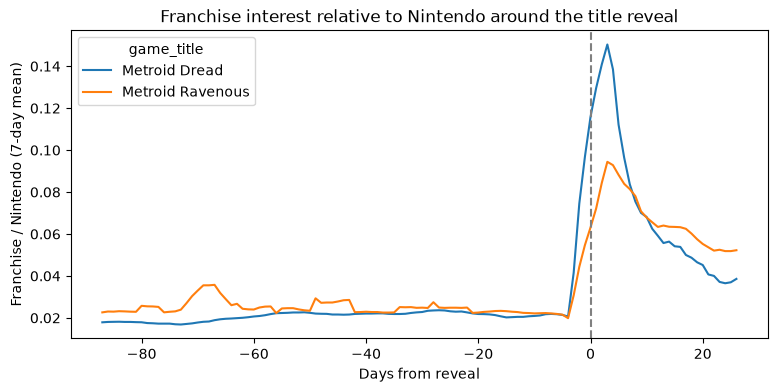

In [31]:
# Daily franchise vs Nintendo ratio for the two Metroid reveals (day 0 = title reveal)
pair = share_daily[share_daily["game_title"].isin(["Metroid Dread", "Metroid Ravenous"])].copy()
pair["share_ratio"] = pair["franchise_interest"] / pair["nintendo_interest"]

# Check: ratio of the sums over the 30 days after the reveal should equal franchise_share_after (0.077 Dread, 0.071 Ravenous)
after = pair[pair["day_offset"] >= 0].groupby("game_title")[["franchise_interest", "nintendo_interest"]].sum()
print((after["franchise_interest"] / after["nintendo_interest"]).round(3))

# Plot with a 7-day rolling mean to smooth daily noise
curves = pair.pivot(index="day_offset", columns="game_title", values="share_ratio").rolling(7, center=True).mean()
ax = curves.plot(figsize=(9, 4))
ax.axvline(0, color="gray", linestyle="--")
ax.set_title("Franchise interest relative to Nintendo around the title reveal")
ax.set_xlabel("Days from reveal")
ax.set_ylabel("Franchise / Nintendo (7-day mean)")
plt.show()

In [32]:
# Export the daily curves for the dashboard (unsmoothed; the dashboard can smooth them)
curves_export = pair[["game_title", "date", "day_offset", "franchise_interest", "nintendo_interest", "share_ratio"]]
curves_export.to_csv(CURVES_FILE, index=False)
print(curves_export.shape)   # expected (240, 6)

(240, 6)


### 7.2 Sales estimate: regression on the 40 games

Model: `log(sales) ~ log(1 + fan base) + time on sale`, fitted with OLS on the analysis sample.
- Sales and fan base are very skewed (1M to 71.5M copies), so both enter in logs. Fan base is measured in searches per 100 "Nintendo"; `log1p` (the log of 1 + x) allows games with a fan base of 0.
- Time on sale is measured up to the date of each sales figure (`sales_age_years`), not up to today, because that is how long each game had been selling when its number was reported.
- **Check 1:** does the reveal jump add anything once fan base is in the model? (The log of `hype_lift` is added as a third variable.)
- **Check 2:** the fitted value for Metroid Dread compared with its real sales.
- The Ravenous estimates use an **80% prediction interval**: the range where the sales of a single new game would fall 8 times out of 10. It is wide because it includes the variation between individual games.

**Reading the coefficients.** In a log-log model, 0.33 on fan base means that doubling (1 + fan base) goes with about 2^0.33 ≈ 1.26 times the copies, so **+26%**. The 0.26 on time on sale means that each extra year goes with about e^0.26 ≈ 1.30 times the copies, so **+30%**.

In [33]:
# Ravenous sales estimate: regression on the 40-game analysis sample
# Model: log(sales) ~ log(1 + fan base) + time on sale
reg_data = master[master["in_group_chart"]].copy()
reg_data["log_sales"] = np.log(reg_data["sales_millions"])
reg_data["log_base"] = np.log1p(reg_data["franchise_size"] * 100)   # searches per 100 Nintendo searches, +1 to allow zeros
reg_data["sales_age_years"] = reg_data["sales_age_days"] / 365.25   # how long each game had been selling when its figure was reported

model = smf.ols("log_sales ~ log_base + sales_age_years", data=reg_data).fit()
print(model.summary().tables[1])                  # coefficients and p-values
print(f"R2: {model.rsquared:.2f} | n = {int(model.nobs)}")

# Check 1: does the reveal jump add anything once fan base is in the model?
model_jump = smf.ols("log_sales ~ log_base + sales_age_years + np.log(hype_lift)", data=reg_data).fit()
print(f"Jump coefficient p-value: {model_jump.pvalues['np.log(hype_lift)']:.2f}")

# Check 2: fitted value for Metroid Dread vs its real sales
is_dread = reg_data["game_title"] == "Metroid Dread"
print(f"Dread: predicted {np.exp(model.fittedvalues[is_dread].iloc[0]):.1f}M, "
      f"actual {reg_data.loc[is_dread, 'sales_millions'].iloc[0]:.2f}M")   # expected: 2.7M vs 3.07M

# Ravenous: estimated sales after 1, 2 and 3 years on sale
ravenous = master[master["game_title"] == "Metroid Ravenous"].copy()
ravenous["log_base"] = np.log1p(ravenous["franchise_size"] * 100)
for years in [1, 2, 3]:
    ravenous["sales_age_years"] = years
    pred = model.get_prediction(ravenous).summary_frame(alpha=0.20)   # 80% prediction interval
    print(f"After {years} year(s): {np.exp(pred['mean'].iloc[0]):.1f}M "
          f"(80% range {np.exp(pred['obs_ci_lower'].iloc[0]):.1f}M to {np.exp(pred['obs_ci_upper'].iloc[0]):.1f}M)")

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.3216      0.283      1.136      0.263      -0.252       0.895
log_base            0.3280      0.073      4.505      0.000       0.181       0.476
sales_age_years     0.2596      0.044      5.845      0.000       0.170       0.350
R2: 0.58 | n = 40
Jump coefficient p-value: 0.35
Dread: predicted 2.7M, actual 3.07M
After 1 year(s): 2.7M (80% range 1.0M to 7.2M)
After 2 year(s): 3.5M (80% range 1.3M to 9.3M)
After 3 year(s): 4.5M (80% range 1.7M to 12.0M)


### 7.3 Cross-check: games with the closest fan base

A second, simpler way to frame Ravenous: the sales of the games whose franchise attention is closest to it. It gives a **range, not a prediction**.

First attempt: closest by attention after the reveal (`franchise_share_after`). It does not work well, because this measure mixes very different games (mega franchises such as Mario Kart and Smash next to Dread, which reached a similar level from a much smaller base). The range is too wide to say anything (1M to 71.5M). It is kept here as a documented dead end.

In [34]:
# Closest games by franchise Share after the reveal (kept as a documented dead end)
rav = master[master["game_title"] == "Metroid Ravenous"].iloc[0]
scenario_pool = master[has_sales & ~master["low_signal_franchise"]].copy()
scenario_pool["distance"] = (scenario_pool["franchise_share_after"] - rav["franchise_share_after"]).abs()

neighbors = scenario_pool.nsmallest(8, "distance")
print(neighbors[["game_title", "franchise_share_after", "franchise_size", "sales_millions", "years_on_market"]])
print(neighbors["sales_millions"].describe().round(2))

                           game_title  franchise_share_after  franchise_size  \
17                Mario Kart 8 Deluxe               0.073550        0.072318   
23                      Metroid Dread               0.076874        0.020058   
39                         Splatoon 3               0.055782        0.028029   
45         Super Mario Party Jamboree               0.055234        0.038789   
8   Fire Emblem Warriors: Three Hopes               0.052632        0.031882   
20             Mario Party Superstars               0.046124        0.030756   
47         Super Smash Bros. Ultimate               0.096447        0.057714   
54              Yoshi's Crafted World               0.044034        0.044061   

    sales_millions  years_on_market  
17           71.53         9.467488  
23            3.07         5.021218  
39           11.96         4.101300  
45           10.37         1.995893  
8             1.00         4.312115  
20           14.00         4.963723  
47           

Second attempt: closest by `franchise_size`, the metric that does relate to sales. The range is about three times narrower. The table is saved for the dashboard.

Read it with care: the neighbors have 4 to 9 years on the market, while Ravenous starts from zero, so older games have accumulated sales for longer. The games most similar in type to Ravenous (single-player action and adventure: Dread, Origami King, Tropical Freeze) sit at the low end of the range; the high end is made of multiplayer and social games (Splatoon, Mario Party). This is an observation, not a filter: no game was excluded.

The low end of this range is consistent with the regression estimate in 7.2.

In [35]:
# Closest games by franchise size before the reveal (the metric that relates to sales)
print(rav[["franchise_size", "franchise_share_after"]])

scenario_pool["distance_size"] = (scenario_pool["franchise_size"] - rav["franchise_size"]).abs()
neighbors_size = scenario_pool.nsmallest(8, "distance_size")
print(neighbors_size[["game_title", "franchise_size", "franchise_share_after", "sales_millions", "years_on_market"]])
print(neighbors_size["sales_millions"].describe().round(2))

# Save the scenario table for the dashboard
scenario = neighbors_size[["game_title", "franchise_size", "franchise_share_after", "sales_millions", "years_on_market"]]
scenario.to_csv(SCENARIO_FILE, index=False)
print(scenario.shape)   # expected (8, 5)

franchise_size           0.024476
franchise_share_after     0.07109
Name: 24, dtype: object
                              game_title  franchise_size  \
7   Donkey Kong Country: Tropical Freeze        0.026686   
38                            Splatoon 2        0.022031   
39                            Splatoon 3        0.028029   
23                         Metroid Dread        0.020058   
20                Mario Party Superstars        0.030756   
8      Fire Emblem Warriors: Three Hopes        0.031882   
44                     Super Mario Party        0.033949   
28         Paper Mario: The Origami King        0.012902   

    franchise_share_after  sales_millions  years_on_market  
7                0.041565            4.62         8.451745  
38               0.041018           13.60         9.237509  
39               0.055782           11.96         4.101300  
23               0.076874            3.07         5.021218  
20               0.046124           14.00         4.963723  
8

## 8. Tables for the dashboard

Six tables are uploaded to BigQuery (project `metroid-hype`, dataset `metroid_hype`) and read by the Data Studio report. Five are created in the sections above; the last one is created here.

| Table | Created in | Used for |
|---|---|---|
| `games_master` | 5.3 | Sample overview, reveal jump ranking, analyst scatter and filters |
| `signals_summary` | 6.1 | Which hype signals go with sales (chart and analyst table) |
| `fan_base_summary` | 6.2 | Reveal jump and sales by fan base group |
| `curves_ravenous_dread` | 7.1 | Daily curves of Ravenous and Dread |
| `scenario_neighbors` | 7.3 | Where Ravenous could land |
| `explore_curves` | 8 | Explore Any Game: any game's curve next to Ravenous |

**`explore_curves`:** for each of the 40 games, its daily interest relative to its own normal level (1 = a normal day before the reveal), stacked with Ravenous's curve, so the dashboard's game picker can show any game next to Ravenous. The scorecard columns (fan base, jump, sales) are filled only on the selected game's rows.

In [36]:
# Explore Any Game: each game's daily searches vs its own normal level, paired with Ravenous
daily = pd.read_csv(DAILY_FILE)

# Normal level = median daily interest in the 90 days before the reveal (same baseline as hype_lift)
baseline = daily[daily["day_offset"] < 0].groupby("game_title")["interest"].median().rename("baseline")
daily = daily.merge(baseline, on="game_title")
daily["times_normal"] = daily["interest"] / daily["baseline"]   # 1 = a normal day before the reveal

compare_games = master.loc[master["in_group_chart"], "game_title"].tolist()   # same 40 games as the rest of the dashboard
ravenous_curve = daily[daily["game_title"] == "Metroid Ravenous"]   # the same Ravenous curve is paired with every game
info = master.set_index("game_title")

parts = []
for game in compare_games:
    game_curve = daily[daily["game_title"] == game].copy()
    game_curve["line"] = "Selected game"
    # Scorecard values only on the selected game's rows (Ravenous rows stay empty)
    game_curve["fan_base_per100"] = info.loc[game, "franchise_size"] * 100
    game_curve["jump_x"] = info.loc[game, "hype_lift"]
    game_curve["sales_m"] = info.loc[game, "sales_millions"]

    rav_curve = ravenous_curve.copy()
    rav_curve["line"] = "Metroid Ravenous"

    game_pair = pd.concat([game_curve, rav_curve])
    game_pair["compare_game"] = game     # the value the drop-down filters on
    parts.append(game_pair)

explore = pd.concat(parts, ignore_index=True)[
    ["compare_game", "line", "day_offset", "date", "times_normal", "fan_base_per100", "jump_x", "sales_m"]]
explore[["times_normal", "fan_base_per100", "jump_x"]] = explore[["times_normal", "fan_base_per100", "jump_x"]].round(2)
explore.to_csv(EXPLORE_FILE, index=False)

# Checks: expected (9600, 8) and 40 games; Dread's average jump after the reveal should be 4.38
print(explore.shape, explore["compare_game"].nunique())
dread = explore[(explore["compare_game"] == "Metroid Dread") & (explore["line"] == "Selected game")]
print("Dread average jump:", round(dread.loc[dread["day_offset"] >= 0, "times_normal"].mean(), 2))

(9600, 8) 40
Dread average jump: 4.38


## 9. Findings and limitations

*Analysis date: 16 October 2026. Google Trends windows: 90 days before to 29 days after each title reveal (for Ravenous, up to 8 October 2026). 55 games, 54 with sales, 40 in the analysis sample.*

### Findings
1. **How many people care goes with sales.** Controlling for time on sale, fan base before the reveal (partial Spearman 0.59, 95% interval 0.30 to 0.77), attention in the month after (0.59, 0.34 to 0.76) and trailer views per day (0.56, 0.23 to 0.76, 33 games) all relate to sales (6.1).
2. **How excited they are does not.** The reveal jump (−0.18, −0.49 to 0.21), days of elevated interest (−0.12, −0.46 to 0.26), trailer like rate (0.02, −0.42 to 0.38) and comment rate (0.05, −0.38 to 0.45, 26 games) show no relation. This is "no evidence", not "no effect": with 40 games a small effect cannot be ruled out.
3. **The reveal adds nothing beyond the fan base.** Controlling for fan base, attention after the reveal is at 0 (−0.00, 44 games, 6.3), and adding the reveal jump to the regression does not help (p = 0.35, 7.2).
4. **Small fan bases jump the most but sell the least.** Median reveal jump 1.72× / 1.07× / 1.07× and median sales 4.04M / 8.42M / 15.07M for small, medium and large fan bases (6.2). A big jump mostly reflects a small starting level. Metroid is in the small group.
5. **Ravenous looks like Dread in attention.** Fan base 2.4 vs 2.0 searches per 100 "Nintendo", attention in the month after 7.1 vs 7.7. Dread had the bigger jump (4.4× vs 2.8×; it was the series' return after 19 years), Ravenous the longer tail (7.1).
6. **Ravenous estimate: about 3.5M copies after two years** (80% range 1.3M to 9.3M), 2.7M after one year and 4.5M after three. The model explains 58% of the variation in (log) sales across the 40 games and predicts 2.7M for Dread (actual 3.07M). The games with the closest fan base sold 1.0M to 21.4M (median 8.3M); those most similar in type (Dread, Origami King, Tropical Freeze) sold 3.1M to 4.6M, in line with the model (7.2, 7.3).
7. **The result does not depend on the specification.** With the broader per-metric samples (44 games for fan base, 43 for the jump) and years on the market as the age control, fan base still relates to sales (0.45, 95% interval 0.17 to 0.65), holds when any single game is removed (0.41 to 0.50) and with sales per year (about 0.4), while the jump stays close to zero. It also holds when whole franchises are resampled (fan base 0.21 to 0.79) and with one row per franchise (0.70 for fan base, −0.38 for the jump) (6.4).

### Limitations

**Sample and method**
- **Small, designed sample.** 40 games in the analysis, so intervals are wide. They assume a random sample, so they are a little optimistic. Seven signals were tested, so one could look significant by chance; the two primary metrics were declared before the analysis.
- **Games of the same franchise are not independent** (7 Pokémon, 5 Super Mario and 5 Zelda games in the analysis sample). Resampling whole franchises widens the intervals but does not change the conclusion (6.4, check 5).
- **Selection on the outcome.** The main group only has games with 4M+ sales. The comparison group (15 games under 4M) softens this, but it is an extremes sample, not representative of all Nintendo games. Wikipedia lists start at 1M, so the lowest figures are milestone lower bounds.
- **14 games left out** for weak Google Trends signals, some of them big sellers (Switch Sports, Ring Fit Adventure, Luigi's Mansion 3). New or generic franchise names are hard to measure with search data.
- **Correlation, not causation.** Big franchises also get more marketing, more shelf space and more coverage.

**Measurement**
- **Hype is measured only in the month after the title reveal.** The months between the reveal and the launch (new trailers, Directs, previews) are not measured, and that period is long: more than 5 months for the median game and almost 5 years for Bayonetta 3.
- **Google Trends** is scaled per query and sampled (values can change by about 1 point between runs, 5.2). Broad terms such as "yoshi" or "super mario" are noisy (the Mario movie inflates the Wonder baseline). Reveals inside a Nintendo Direct also raise searches for "Nintendo" itself, and shared events (Switch 2 Direct on 2025-04-02, Mario Direct on 2020-09-03) inflate shared measurements; a sensitivity run excludes those games.
- **Search terms are in English and searched worldwide**, so searches written in other scripts (for example Japanese) are missed. Franchises that sell mostly in Japan can be under-measured.
- **Game-name searches undercount attention** (Ravenous 0.012 vs Dread 0.027 by name, but 0.071 vs 0.077 by franchise), so the franchise term is used.
- **YouTube:** engagement only uses trailers from Nintendo of America and the official Pokémon channel (33 of the 40 games). Third-party re-uploads, Nintendo's Japanese channel and shared videos are excluded, and 8 games have comments turned off (stored as empty).

**Sales data**
- **Sales figures** come from Wikipedia (mostly Nintendo's official reports) at different dates. Time on sale controls for this, but Switch 2 figures are still immature. The lists are per console: when a game also has a Switch 2 Edition, those sales are listed separately and were not added.
- **Price, bundles and discounts were not modeled.** Most games launched at the standard full price (€60 in Europe, or the regional equivalent), but some launched higher (e.g. Tears of the Kingdom at about €70, Mario Kart World at €80 or more). Some best sellers were also sold in console bundles (Mario Kart World with the Switch 2, Mario Kart 8 Deluxe in several Switch bundles), and bundled copies count as sales. Later discounts were not tracked either.
- **Ports and remakes are mixed with new games.** Mario Kart 8 Deluxe, for example, had already been released on Wii U, so its reveal and its sales may not behave like those of a new game.
- **The size of each console's player base at launch is not controlled.** Early Switch games and Switch 2 games launched to fewer players than games released in the middle of the Switch's life.

**Metroid and Ravenous**
- **Dread** was the series' comeback after about 19 years, and the Ravenous title leaked in Brazil about 68 days before the reveal.
- **Other recent Metroid games are not in the sample.** Metroid Prime 4: Beyond (December 2025) is not in the per-console Wikipedia lists (Nintendo announced over 1 million copies across Switch and Switch 2 combined). Metroid Prime Remastered was in the comparison pool but was not drawn (3.3).
- **The Ravenous estimate** has a wide range and does not include the Switch 2 installed base, marketing spend or release timing.

### Next steps
- Repeat the analysis after the launch (January 2027) with real Ravenous sales and compare them with the estimate in section 7.
- Add other publishers and platforms to test whether the result holds beyond Nintendo.
- Measure hype over the whole period from the reveal to the launch, not only the first month.
- Add signals closer to purchase intent, such as pre-orders or wishlists, and analyze what fans say in trailer comments.